# Limiarização por degrau (manual)

O "Otsu de braço": variar T na mão para entender o que o Otsu automatiza.


In [1]:
import sys
from pathlib import Path

# O kernel inicia na pasta DESTE caderno — localiza a raiz do projeto:
RAIZ = Path.cwd()
if not (RAIZ / "src" / "leitura.py").exists():
    RAIZ = RAIZ.parent          # kernel começou dentro de notebooks/
sys.path.insert(0, str(RAIZ))   # raiz no path -> 'from src...' funciona

# Imports padrão de todos os cadernos:
from src.leitura import (PASTA_IMAGENS, PASTA_RESULTADOS, carregar_imagem,
                         nome_da_mascara, criar_pastas_resultados, auditar_base)
import cv2
import numpy as np
import matplotlib.pyplot as plt

print("raiz do projeto:", RAIZ)

raiz do projeto: /home/isadora/Documentos/ProcessIMg


In [2]:
from src.preprocessamento import para_cinza
from src.segmentacao import binarizar

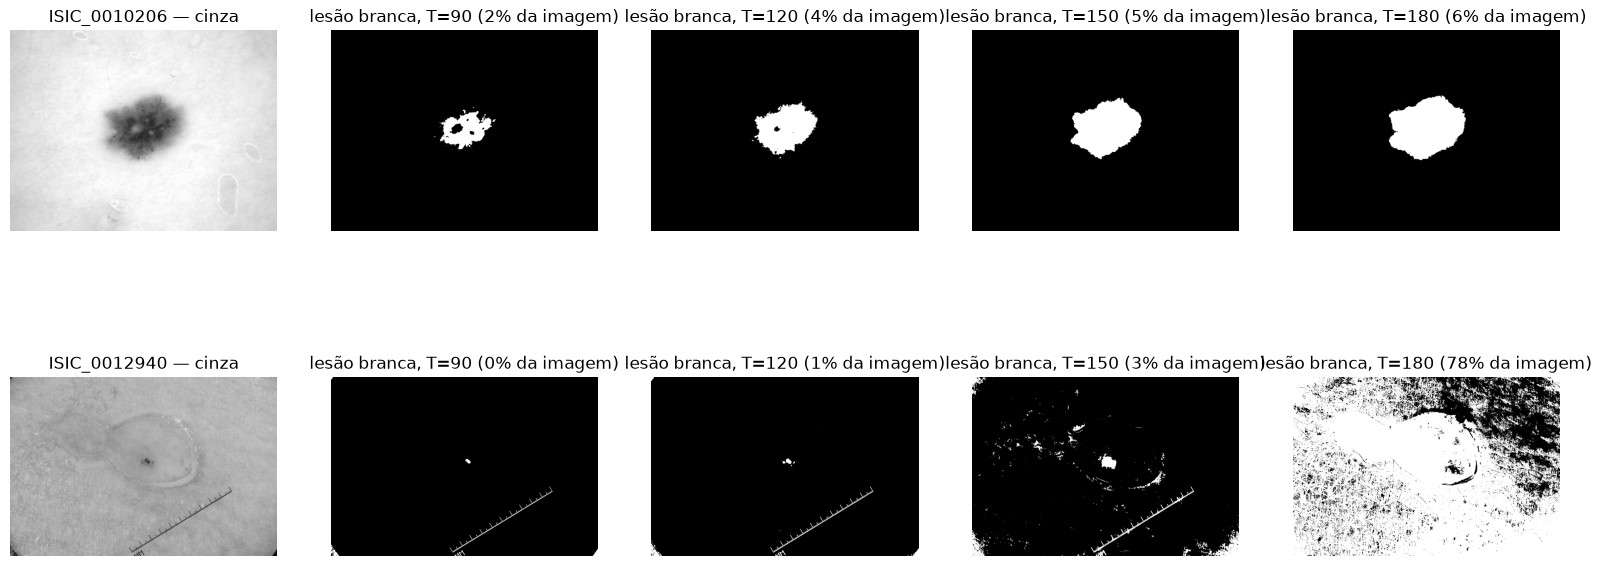

In [3]:
alvo = PASTA_RESULTADOS / "segmentadas"
limiares = [90, 120, 150, 180]

fig, axes = plt.subplots(2, 5, figsize=(20, 8))
for i, nome in enumerate(["ISIC_0010206.jpg", "ISIC_0012940.jpg"]):
    cinza = para_cinza(carregar_imagem(PASTA_IMAGENS / nome))
    nome_curto = Path(nome).stem

    axes[i, 0].imshow(cinza, cmap="gray", vmin=0, vmax=255)
    axes[i, 0].set_title(f"{nome_curto} — cinza")
    for j, t in enumerate(limiares, start=1):
        msk = binarizar(cinza, t, invertida=True)   # lesão é escura -> lesão fica branca
        frac = msk.mean() / 255
        axes[i, j].imshow(msk, cmap="gray", vmin=0, vmax=255)
        axes[i, j].set_title(f"lesão branca, T={t} ({frac*100:.0f}% da imagem)")
    for ax in axes[i]:
        ax.axis("off")

fig.savefig(alvo / "limiarizacao_degrau.png", bbox_inches="tight", dpi=150)
plt.show()
plt.close(fig)